# Seasonal Agriculture Performance Analysis
**VOIS AICTE Data Analytics Internship — Major Project**

**Objective:** Analyze agricultural data across seasons (Kharif, Rabi, Zaid) to identify meaningful patterns, trends, relationships, and differences in agricultural performance, and develop evidence-based conclusions and recommendations.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100
%matplotlib inline

## 2. Load the Dataset

In [2]:
df = pd.read_csv('seasonal_agriculture_performance_dataset.csv')
df.head()

   Farm_ID  ... Disease_Pest_Risk_pct
0  SF10001  ...                  55.3
1  SF10002  ...                  49.9
2  SF10003  ...                  33.7
3  SF10004  ...                  50.6
4  SF10005  ...                  32.3

[5 rows x 28 columns]

In [3]:
df.tail()

      Farm_ID  ... Disease_Pest_Risk_pct
3995  SF13996  ...                  45.2
3996  SF13997  ...                  59.7
3997  SF13998  ...                  29.2
3998  SF13999  ...                  50.4
3999  SF14000  ...                  62.3

[5 rows x 28 columns]

## 3. Initial Data Exploration

In [4]:
print("Shape of the dataset (rows, columns):", df.shape)

Shape of the dataset (rows, columns): (4000, 28)


In [5]:
df.columns

Index(['Farm_ID', 'State', 'District', 'Crop', 'Season', 'Farm_Area_Hectares',
       'Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct',
       'Sunlight_Hours_Day', 'Soil_pH', 'Soil_Moisture_pct', 'Nitrogen_kg_ha',
       'Phosphorus_kg_ha', 'Potassium_kg_ha', 'Irrigation_Method',
       'Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Seed_Quality_Score',
       'Yield_Tonnes_Ha', 'Production_Tonnes', 'Market_Price_INR_Tonne',
       'Total_Cost_INR', 'Revenue_INR', 'Profit_INR', 'Water_Used_m3',
       'Water_Efficiency_t_per_1000m3', 'Disease_Pest_Risk_pct'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   str    
 1   State                          4000 non-null   str    
 2   District                       4000 non-null   str    
 3   Crop                           4000 non-null   str    
 4   Season                         4000 non-null   str    
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   float64
 13 

In [7]:
df.describe()

       Farm_Area_Hectares  ...  Disease_Pest_Risk_pct
count         4000.000000  ...            4000.000000
mean             7.888265  ...              46.365875
std              4.223764  ...              12.424417
min              0.500000  ...               5.000000
25%              4.260000  ...              37.300000
50%              7.895000  ...              46.400000
75%             11.650000  ...              54.900000
max             15.000000  ...              88.900000

[8 rows x 22 columns]

**Observations:**
- The dataset has 4000 records and 28 columns.
- It contains 5 categorical columns (State, District, Crop, Season, Irrigation_Method) and 23 numerical columns covering environmental conditions, farming inputs, and economic outcomes.
- `Season` has 3 categories: Kharif, Rabi, and Zaid — this is our key grouping variable for the analysis.

## 4. Data Cleaning

### 4.1 Check for Missing Values

In [8]:
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df[missing_df['Missing Count'] > 0]

                   Missing Count  Missing %
Rainfall_mm                   48        1.2
Soil_Moisture_pct             40        1.0
Yield_Tonnes_Ha               32        0.8

We have missing values in three numeric columns: `Rainfall_mm`, `Soil_Moisture_pct`, and `Yield_Tonnes_Ha`. Since these values are highly dependent on the season (e.g. Kharif is the monsoon season with much higher rainfall than Zaid), filling them with the **overall** median would distort the season-wise patterns we want to study. Instead, we fill missing values with the **median of their own season**.

### 4.2 Handle Missing Values (Season-wise Median Imputation)

In [9]:
for col in ['Rainfall_mm', 'Soil_Moisture_pct', 'Yield_Tonnes_Ha']:
    df[col] = df.groupby('Season')[col].transform(lambda x: x.fillna(x.median()))

print("Missing values remaining:", df.isnull().sum().sum())

Missing values remaining: 0


### 4.3 Check for Duplicate Records

In [10]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


No duplicate records were found, so no rows need to be dropped.

### 4.4 Verify Data Types

In [11]:
df.dtypes

Farm_ID                              str
State                                str
District                             str
Crop                                 str
Season                               str
Farm_Area_Hectares               float64
Rainfall_mm                      float64
Avg_Temperature_C                float64
Humidity_pct                     float64
Sunlight_Hours_Day               float64
Soil_pH                          float64
Soil_Moisture_pct                float64
Nitrogen_kg_ha                   float64
Phosphorus_kg_ha                 float64
Potassium_kg_ha                  float64
Irrigation_Method                    str
Fertilizer_kg_ha                 float64
Pesticide_Litre_ha               float64
Seed_Quality_Score               float64
Yield_Tonnes_Ha                  float64
Production_Tonnes                float64
Market_Price_INR_Tonne             int64
Total_Cost_INR                     int64
Revenue_INR                        int64
Profit_INR      

All numeric columns are already in the correct numeric format (int64/float64), and categorical columns (State, District, Crop, Season, Irrigation_Method) are stored as text. No type conversion is required.

## 5. Univariate Analysis
*(Examining one variable at a time)*

### 5.1 Distribution of Records Across Seasons

Season
Kharif    1779
Rabi      1627
Zaid       594
Name: count, dtype: int64


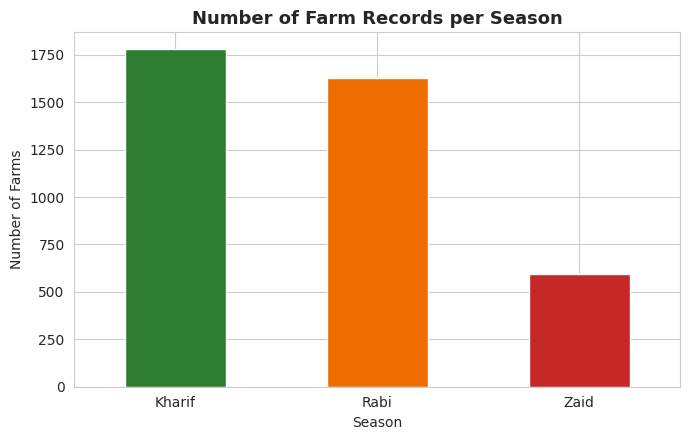

In [12]:
season_counts = df['Season'].value_counts()
print(season_counts)

plt.figure(figsize=(7,4.5))
season_counts.plot(kind='bar', color=['#2E7D32','#EF6C00','#C62828'])
plt.title('Number of Farm Records per Season', fontsize=13, fontweight='bold')
plt.xlabel('Season')
plt.ylabel('Number of Farms')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:** Kharif has the most farm records (1779), followed by Rabi (1627), and Zaid has considerably fewer (594) — reflecting that Zaid is a shorter, less commonly cultivated season.

### 5.2 Distribution of Crops Grown

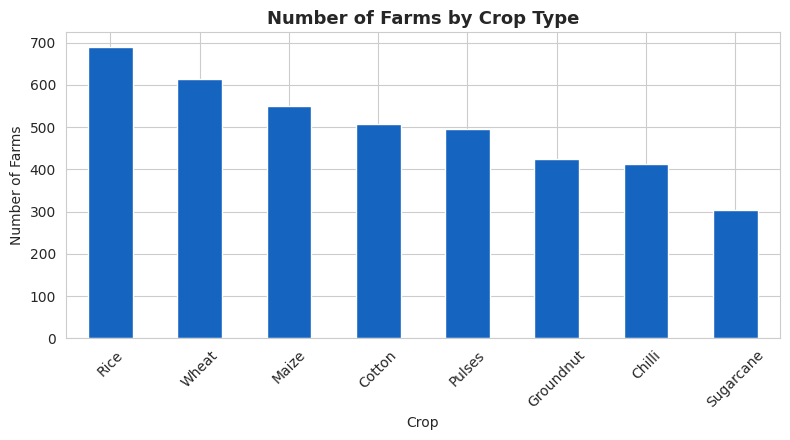

In [13]:
plt.figure(figsize=(8,4.5))
df['Crop'].value_counts().plot(kind='bar', color='#1565C0')
plt.title('Number of Farms by Crop Type', fontsize=13, fontweight='bold')
plt.xlabel('Crop')
plt.ylabel('Number of Farms')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5.3 Distribution of Yield

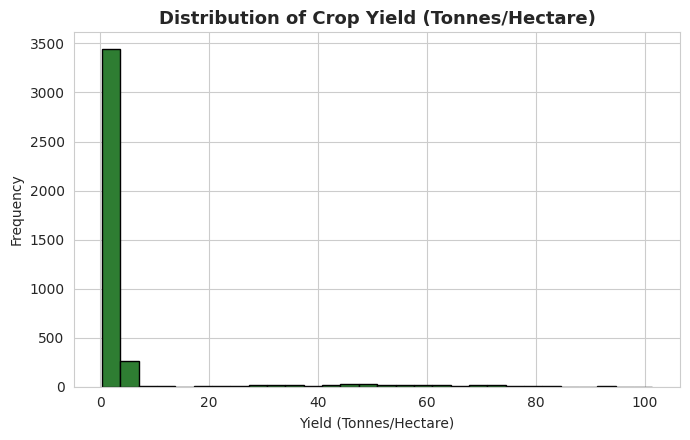

In [14]:
plt.figure(figsize=(7,4.5))
df['Yield_Tonnes_Ha'].plot(kind='hist', bins=30, color='#2E7D32', edgecolor='black')
plt.title('Distribution of Crop Yield (Tonnes/Hectare)', fontsize=13, fontweight='bold')
plt.xlabel('Yield (Tonnes/Hectare)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

**Insight:** Yield is right-skewed — most farms produce between 1 and 8 tonnes/hectare, but a small number of high-performing farms pull the distribution's tail out further.

## 6. Bivariate Analysis
*(Examining the relationship between two variables — Season vs. key performance metrics)*

### 6.1 Average Yield by Season

Season
Kharif    5.629438
Rabi      5.038451
Zaid      4.638872
Name: Yield_Tonnes_Ha, dtype: float64


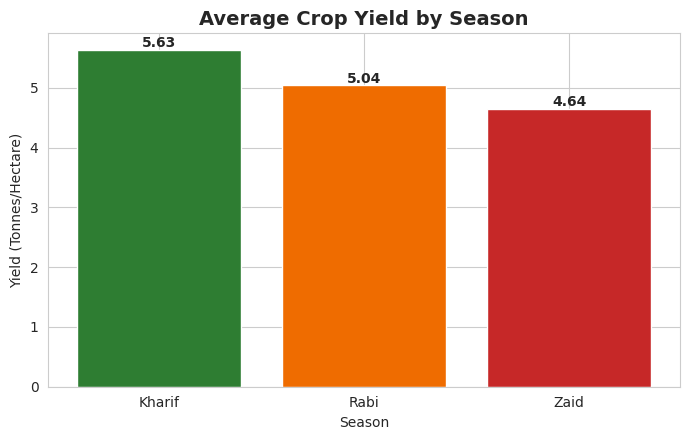

In [15]:
season_order = ['Kharif','Rabi','Zaid']
palette = {'Kharif':'#2E7D32','Rabi':'#EF6C00','Zaid':'#C62828'}

yield_by_season = df.groupby('Season')['Yield_Tonnes_Ha'].mean().reindex(season_order)
print(yield_by_season)

fig, ax = plt.subplots(figsize=(7,4.5))
bars = ax.bar(yield_by_season.index, yield_by_season.values, color=[palette[s] for s in season_order])
ax.set_title('Average Crop Yield by Season', fontsize=14, fontweight='bold')
ax.set_ylabel('Yield (Tonnes/Hectare)')
ax.set_xlabel('Season')
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x()+bar.get_width()/2, h+0.05, f'{h:.2f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('images/1_yield_by_season.png')
plt.show()

**Insight:** Kharif delivers the highest average yield (5.63 t/ha), followed by Rabi (5.04 t/ha) and Zaid (4.64 t/ha).

### 6.2 Average Rainfall and Profit by Season

Avg Rainfall:
 Season
Kharif    852.112676
Rabi      435.937062
Zaid      299.123232
Name: Rainfall_mm, dtype: float64

Avg Profit:
 Season
Kharif    178914.647555
Rabi       87689.470191
Zaid      -24804.824916
Name: Profit_INR, dtype: float64


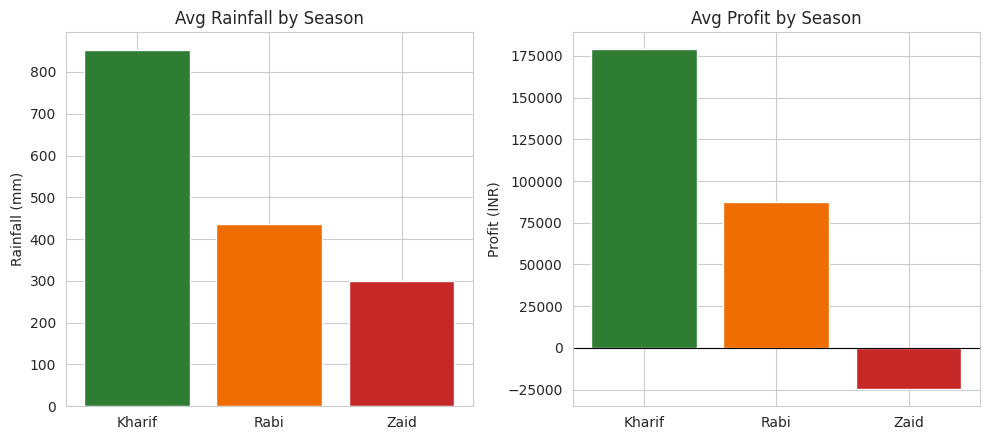

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10,4.5))
rain = df.groupby('Season')['Rainfall_mm'].mean().reindex(season_order)
profit = df.groupby('Season')['Profit_INR'].mean().reindex(season_order)
print("Avg Rainfall:\n", rain)
print("\nAvg Profit:\n", profit)

axes[0].bar(rain.index, rain.values, color=[palette[s] for s in season_order])
axes[0].set_title('Avg Rainfall by Season')
axes[0].set_ylabel('Rainfall (mm)')
axes[1].bar(profit.index, profit.values, color=[palette[s] for s in season_order])
axes[1].set_title('Avg Profit by Season')
axes[1].set_ylabel('Profit (INR)')
axes[1].axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('images/2_rainfall_profit_by_season.png')
plt.show()

**Insight:** This is one of the most important findings in the whole project:
- Kharif (monsoon season) gets ~852mm average rainfall and is the **most profitable** season (avg profit ₹1.79 lakh/farm).
- Zaid (summer season) gets only ~299mm rainfall and runs an **average loss** of ₹24,805/farm.
- 64.5% of Zaid farms operate at a net loss, compared to 51% in Rabi and 42% in Kharif.

### 6.3 Relationship Between Rainfall and Yield

Correlation (Rainfall vs Yield): 0.029


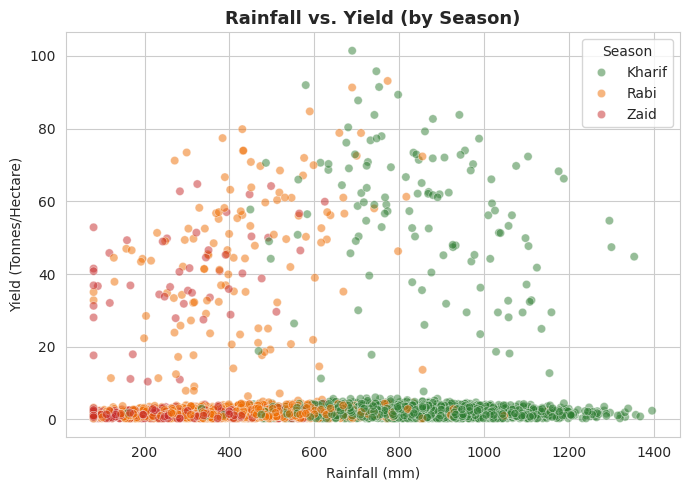

In [17]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='Rainfall_mm', y='Yield_Tonnes_Ha', hue='Season', palette=palette, alpha=0.5)
plt.title('Rainfall vs. Yield (by Season)', fontsize=13, fontweight='bold')
plt.xlabel('Rainfall (mm)')
plt.ylabel('Yield (Tonnes/Hectare)')
plt.tight_layout()
plt.show()

print("Correlation (Rainfall vs Yield):", round(df['Rainfall_mm'].corr(df['Yield_Tonnes_Ha']), 3))

**Insight:** Surprisingly, rainfall and yield are almost uncorrelated (r ≈ 0.03) — irrigation and soil/fertilizer management appear to compensate for natural rainfall differences at the farm level.

## 7. Multivariate Analysis
*(Examining relationships across 3+ variables)*

### 7.1 Correlation Heatmap of Key Metrics

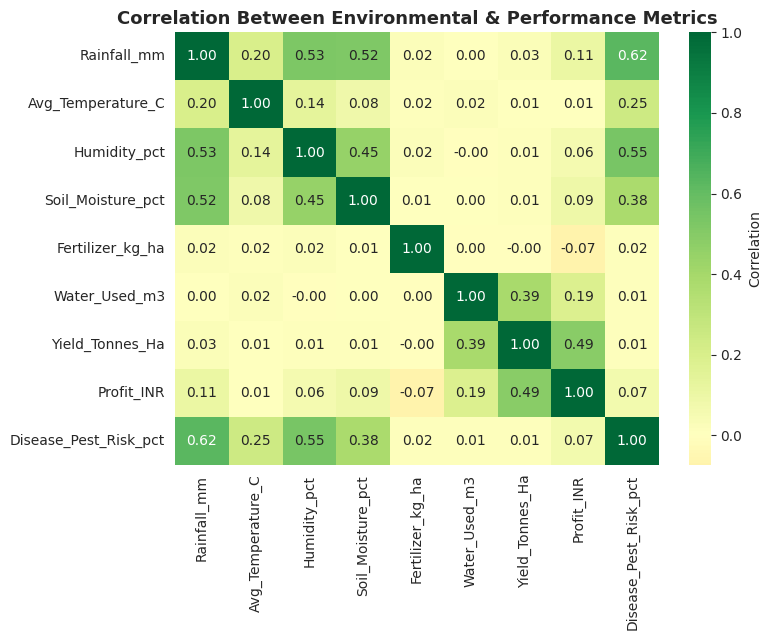

In [18]:
key_cols = ['Rainfall_mm','Avg_Temperature_C','Humidity_pct','Soil_Moisture_pct',
            'Fertilizer_kg_ha','Water_Used_m3','Yield_Tonnes_Ha','Profit_INR','Disease_Pest_Risk_pct']
corr = df[key_cols].corr()

fig, ax = plt.subplots(figsize=(8,6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn', center=0, ax=ax, cbar_kws={'label':'Correlation'})
ax.set_title('Correlation Between Environmental & Performance Metrics', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('images/3_correlation_heatmap.png')
plt.show()

**Insight:** Rainfall correlates strongly with Disease/Pest Risk (r = 0.62) — higher rainfall seasons see more pest and disease pressure, which likely offsets some of the yield benefit of extra water. Profit correlates most with Yield (r = 0.49), which makes intuitive sense.

### 7.2 Average Yield by Season & Irrigation Method

Irrigation_Method      Drip     Flood   Rainfed  Sprinkler
Season                                                    
Kharif             7.256296  4.979339  5.704903   4.662897
Rabi               6.109946  5.059677  3.928744   5.306143
Zaid               5.848143  3.978402  3.063786   6.133417


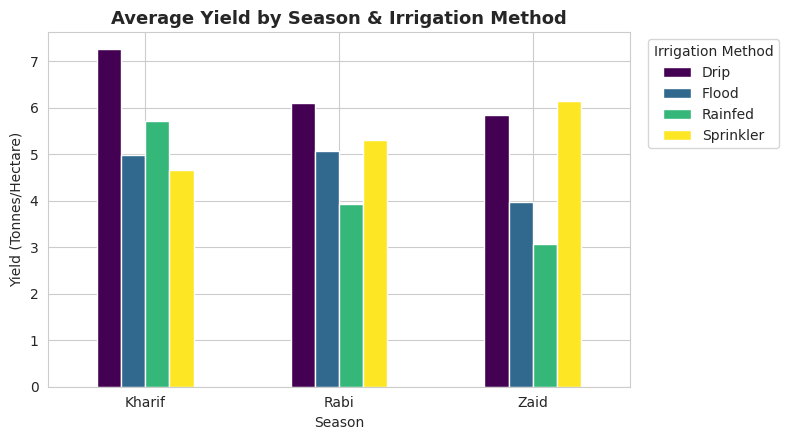

In [19]:
pivot = df.pivot_table(index='Season', columns='Irrigation_Method', values='Yield_Tonnes_Ha', aggfunc='mean').reindex(season_order)
print(pivot)

fig, ax = plt.subplots(figsize=(8,4.5))
pivot.plot(kind='bar', ax=ax, colormap='viridis')
ax.set_title('Average Yield by Season & Irrigation Method', fontsize=13, fontweight='bold')
ax.set_ylabel('Yield (Tonnes/Hectare)')
ax.set_xlabel('Season')
plt.xticks(rotation=0)
plt.legend(title='Irrigation Method', bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.savefig('images/4_yield_by_season_irrigation.png')
plt.show()

**Insight:** Drip irrigation gives the highest yield in Kharif and Rabi. But in Zaid, Sprinkler irrigation outperforms Drip — likely because Zaid's high temperatures and low rainfall make sprinkler's broader coverage more effective at that time of year.

### 7.3 Disease & Pest Risk Distribution by Season

Season
Kharif    54.467903
Rabi      40.482114
Zaid      38.216667
Name: Disease_Pest_Risk_pct, dtype: float64


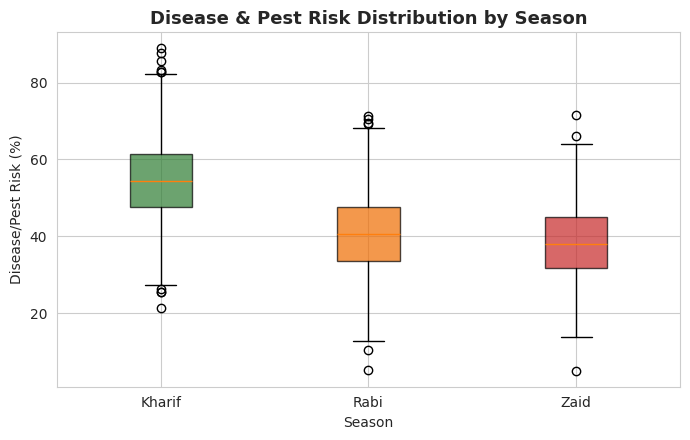

In [20]:
fig, ax = plt.subplots(figsize=(7,4.5))
data_by_season = [df[df['Season']==s]['Disease_Pest_Risk_pct'] for s in season_order]
bp = ax.boxplot(data_by_season, tick_labels=season_order, patch_artist=True)
for patch, s in zip(bp['boxes'], season_order):
    patch.set_facecolor(palette[s])
    patch.set_alpha(0.7)
ax.set_title('Disease & Pest Risk Distribution by Season', fontsize=13, fontweight='bold')
ax.set_ylabel('Disease/Pest Risk (%)')
ax.set_xlabel('Season')
plt.tight_layout()
plt.savefig('images/5_disease_risk_by_season.png')
plt.show()

print(df.groupby('Season')['Disease_Pest_Risk_pct'].mean().reindex(season_order))

**Insight:** Kharif has the highest average disease/pest risk (54.5%) due to high rainfall and humidity, while Zaid has the lowest (38.2%) — confirming the correlation found above.

## 8. Key Questions Answered

1. **How does agricultural performance vary across seasons?** Kharif performs best on yield and profit, Zaid performs worst, with Rabi in between.
2. **What major seasonal patterns can be observed?** Rainfall, disease/pest risk, and profit all move together across seasons — higher rainfall (Kharif) brings higher yield and profit, but also higher pest/disease risk.
3. **Which characteristics change between seasons?** Rainfall, temperature, disease/pest risk, and irrigation-method effectiveness all shift notably between seasons.
4. **Are there relationships between seasonal environmental conditions and agricultural performance?** Yes — rainfall is strongly linked to disease/pest risk (r=0.62), while yield is largely independent of rainfall (r≈0.03) and more dependent on irrigation choice and water usage.
5. **How do economic outcomes vary across seasons?** Kharif farms average a profit of ₹1.79 lakh; Zaid farms average a **loss** of ₹24,805 — a major finding for planning purposes.
6. **Are some seasonal patterns consistent across regions/categories?** Drip irrigation is consistently the best performer in Kharif and Rabi, but Sprinkler overtakes it in Zaid — indicating irrigation strategy should be season-specific, not one-size-fits-all.

## 9. Conclusions & Recommendations

**Conclusions:**
- Zaid is the highest-risk season financially — nearly two-thirds of Zaid farms operate at a loss, driven by low rainfall and lower yields.
- Kharif is the most productive and profitable season but carries the highest disease/pest risk due to high rainfall and humidity.
- Yield is driven more by irrigation method and water management than by rainfall itself.

**Recommendations:**
- Farmers cultivating in the Zaid season should prioritize Sprinkler irrigation over Drip, based on observed yield performance.
- Increased investment in pest/disease control (biopesticides, monitoring) is advisable in Kharif season to protect against the higher risk associated with high rainfall.
- Since rainfall alone doesn't guarantee yield, agricultural planning should prioritize irrigation infrastructure and water-use efficiency over rainfall dependency, especially in low-rainfall seasons like Zaid.
- Financial/credit support programs for farmers could be seasonally weighted, with additional support offered during the higher-risk Zaid season.